# Buckley-Leverett fronts

Buckley-Leverett describes a one-dimensional waterflood from an injector to a
producer: the saturation profile and how fast the front moves. Relative
permeability here is Brooks–Corey.

This is the check you run on a pair that CRM says is strongly connected. A large
$f_{ij}$ with a small $\tau_{ij}$ should be a short, permeable path — consistent
with a fast front. It does not replace CRM; it explains one pipe.


In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pywaterflood.buckleyleverett import Reservoir, breakthrough_sw, water_front_velocity


## Rock and fluid

`Reservoir` holds porosity, viscosities (Pa·s), residual saturations, Brooks–Corey
exponents, and the flow area (m²). Saturations and porosity are fractions in
`(0, 1]`. Exponents are in `[1, 6]`.


In [2]:
rock = Reservoir(
    phi=0.25,
    viscosity_oil=4.2e-3,
    viscosity_water=1e-3,
    sat_oil_r=0.2,
    sat_water_c=0.1,
    sat_gas_c=0.05,
    n_oil=2,
    n_water=2,
    flow_cross_section=1.0,
)
sw_bt = breakthrough_sw(rock)
print(f"Breakthrough water saturation Sw,bt = {sw_bt:.3f}")
print(f"Mobile oil at breakthrough = {1 - rock.sat_oil_r - sw_bt:.3f}")


Breakthrough water saturation Sw,bt = 0.100
Mobile oil at breakthrough = 0.700


## Front velocity vs saturation

Above breakthrough, speed follows $\frac{q_t}{\phi A}\partial f_w / \partial S_w$.
Below breakthrough, speed equals the front speed. Units: $q$ in m³/d → $v$ in m/d.


front speed at breakthrough = 0.000 m/d


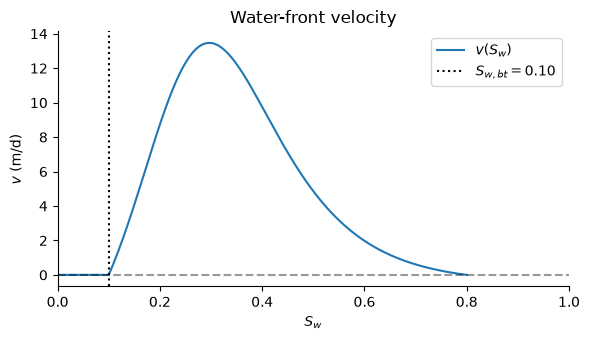

In [3]:
flow_rate = 1.0  # m³/d
saturations = np.linspace(0.0, 1.0 - rock.sat_oil_r, 250)
velocity = np.array([water_front_velocity(rock, sw, flow_rate) for sw in saturations])
v_bt = water_front_velocity(rock, sw_bt, flow_rate)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(saturations, velocity, label=r"$v(S_w)$")
ax.axvline(sw_bt, color="k", ls=":", label=fr"$S_{{w,bt}}={sw_bt:.2f}$")
ax.axhline(v_bt, color="k", ls="--", alpha=0.4)
ax.set(xlim=(0, 1), xlabel=r"$S_w$", ylabel=r"$v$ (m/d)", title="Water-front velocity")
ax.legend()
sns.despine()
fig.tight_layout()
print(f"front speed at breakthrough = {v_bt:.3f} m/d")


## Saturation profiles in time

Each saturation travels at its own speed. Plotting $x = v(S_w)\, t$ gives the
classic Buckley-Leverett profile marching toward the producer.


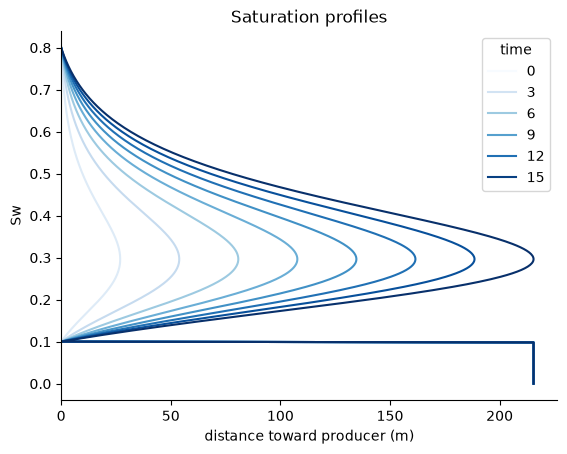

In [4]:
s_w = np.linspace(0.0, 1.0 - rock.sat_oil_r, 400)
v = np.array([water_front_velocity(rock, sw, flow_rate) for sw in s_w])
times = np.arange(0, 17, 2)
frames = [pd.DataFrame({"time": t, "Sw": s_w, "x_front": v * t}) for t in times]
df = pd.concat(frames, ignore_index=True)
x_max = df["x_front"].max()
df.loc[df["Sw"] <= rock.sat_water_c, "x_front"] = x_max

g = sns.lineplot(df, x="x_front", y="Sw", hue="time", orient="y", palette="Blues")
g.set(xlim=(0, None), xlabel="distance toward producer (m)", title="Saturation profiles")
sns.despine()


## Tie-in to CRM

If CRM gives a pair $(f_{ij}, \tau_{ij})$ and you know the well spacing $L$:

- travel time $\approx L / v(S_{w,bt})$ should be the same order as $\tau_{ij}$
  (CRM $\tau$ is a tank lag, not a pure delay, so expect agreement in magnitude
  rather than equality)
- a large $f_{ij}$ with a travel time much longer than $\tau_{ij}$ is a warning
  that the pair is a mathematical fit, not a short path

Use the MPI notebook to seed pairs from geometry, CRM to history-match, and this
front speed as a physics check on the pairs you would actually act on (rate
reallocation, infill, conformance).


In [5]:
spacing_m = 250.0
t_travel = spacing_m / v_bt
print(f"spacing {spacing_m:.0f} m  |  breakthrough travel time {t_travel:.1f} days")
print("Compare that magnitude to CRM τ on the same pair after a history match.")


spacing 250 m  |  breakthrough travel time 29166625.0 days
Compare that magnitude to CRM τ on the same pair after a history match.
